In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
import time

# Лабораторная работа №1.

Число с плавающей точкой хранится в нормализованном виде

$$x = \pm(1.\gamma_1\gamma_2\ldots\gamma_{p-1})_2 \cdot 2^E,$$

то есть кроме порядка $E$ хранится только $p-1$ бит **мантиссы** (ведущая единица не хранится — она и так всегда 1 у нормализованных чисел). Значит расстояние между соседними представимыми числами возле единицы равно $2^{1-p}$ — это и есть **машинный эпсилон**:

$$\varepsilon = \mathrm{nextafter}(1,+\infty) - 1 = 2^{1-p}.$$

Величина $u=\varepsilon/2$  — максимальная относительная ошибка округления одной арифметической операции при округлении к ближайшему.

### Идея алгоритма

Будем делить пробное значение `eps` пополам, пока не найдём границу — то самое число, которое **ещё** меняет единицу при сложении, а его половина — уже нет:

$$1+\varepsilon \neq 1, \qquad 1+\varepsilon/2 = 1.$$

Это прямое следствие того, что сетка чисел с плавающей точкой **дискретна**: между $1$ и следующим представимым числом $1+\varepsilon$ никаких других чисел нет, поэтому любая добавка меньше $\varepsilon/2$ округляется обратно в $1$.

In [2]:
def find_eps(dtype): 
    one = dtype(1.0)
    eps = dtype(1.0)
    p = 0
    while one + eps / dtype(2.0) != one:
        eps = eps / dtype(2.0)
        p += 1
    return eps, p

eps32, p32 = find_eps(np.float32)
eps64, p64 = find_eps(np.float64)

u32, u64 = eps32 / 2, eps64 / 2

print("binary32: eps =", eps32, " u =", u32, " p =", p32)
print("binary64: eps =", eps64, " u =", u64, " p =", p64)


binary32: eps = 1.1920929e-07  u = 5.9604645e-08  p = 23
binary64: eps = 2.220446049250313e-16  u = 1.1102230246251565e-16  p = 52


Число итераций `p` равно числу двоичных цифр мантиссы (для `binary32` это $p=24$: 23 хранимых бита + 1 неявный, для `binary64` — $p=53$: 52 хранимых бита + 1 неявный), что сходится с формулой $\varepsilon = 2^{1-p}$.

Диапазон значений порядка $E$ в IEEE754 ограничен: если продолжать увеличивать порядок, рано или поздно число перестаёт помещаться в отведённые биты экспоненты, и результат операции становится $+\infty$

### Идея алгоритма

Удваиваем число, пока результат ещё конечен. Последняя конечная степень двойки — это и есть $2^{E_{\max}}$.

In [3]:
def find_Emax(dtype):
    x = dtype(1.0)
    k = 0
    with np.errstate(over="ignore"):
        while not math.isinf(float(x * dtype(2.0))):
            x = x * dtype(2.0)
            k += 1
    return k, x

Emax32, pow2_max32 = find_Emax(np.float32)
Emax64, pow2_max64 = find_Emax(np.float64)

print("binary32: E_max =", Emax32)
print("binary64: E_max =", Emax64)


binary32: E_max = 127
binary64: E_max = 1023


Замечание. Диапазон смещённого порядка выбран так, чтобы форматы были симметричны относительно единицы: $E_{\min} = 1-E_{\max}$.

### Минимальный порядок, субнормальные числа, максимум


По лекции, у чисел с плавающей точкой есть три важных предельных значения:

- **минимальное нормальное число** $n_{\min}=2^{E_{\min}}$ — граница, ниже которой ведущая цифра мантиссы больше не может быть «1» при полном наборе разрядов;
- **минимальное субнормальное число** $s_{\min}$ — стандарт IEEE754 не «обнуляет» числа резко, а вводит **субнормальные числа** (denormals) — они позволяют **плавно** (gradual underflow) приближаться к нулю ценой потери точности (мантисса больше не нормализована);
- **максимальное конечное число** $x_{\max} = (2-\varepsilon)\cdot 2^{E_{\max}}$ — мантисса «все единицы» ($1.11\ldots1_2 = 2-2^{1-p}=2-\varepsilon$), умноженная на предельный порядок.

### Идея алгоритма

- Для $n_{\min}$: делим на 2, пока добавка `x*eps` (шаг сетки) ещё "видна" на фоне `x` — как только она станет меньше половины шага, добавление перестанет менять число, это и есть признак выхода из области нормальных чисел.
- Для $s_{\min}$: продолжаем делить $n_{\min}$ пополам — субнормальные числа образуют сетку с **постоянным** (не плавающим) шагом, она обрывается в ноль, последнее ненулевое значение и есть $s_{\min}$.
- Для $x_{\max}$: берём последнюю конечную степень двойки из пункта 2 и умножаем на мантиссу «все единицы» $2-\varepsilon$.

In [4]:
def find_nmin(dtype, eps):
    x = dtype(1.0)
    while (x / dtype(2.0)) + (x / dtype(2.0)) * eps != x / dtype(2.0):
        x = x / dtype(2.0)
    return x

def find_smin(nmin, dtype):
    x = nmin
    while x / dtype(2.0) != dtype(0.0):
        x = x / dtype(2.0)
    return x

def find_xmax(dtype, eps, pow2_max):
    return (dtype(2.0) - eps) * pow2_max

nmin32 = find_nmin(np.float32, eps32)
nmin64 = find_nmin(np.float64, eps64)

smin32 = find_smin(nmin32, np.float32)
smin64 = find_smin(nmin64, np.float64)

xmax32 = find_xmax(np.float32, eps32, pow2_max32)
xmax64 = find_xmax(np.float64, eps64, pow2_max64)

print("binary32: n_min =", float(nmin32), " s_min =", float(smin32), " x_max =", float(xmax32))
print("binary64: n_min =", float(nmin64), " s_min =", float(smin64), " x_max =", float(xmax64))


binary32: n_min = 1.1754943508222875e-38  s_min = 1.401298464324817e-45  x_max = 3.4028234663852886e+38
binary64: n_min = 2.2250738585072014e-308  s_min = 5e-324  x_max = 1.7976931348623157e+308


Все три величины согласуются со стандартными табличными значениями IEEE754:

- `binary32`: $n_{\min}\approx1.18\cdot10^{-38}$, $s_{\min}\approx1.40\cdot10^{-45}$, $x_{\max}\approx3.40\cdot10^{38}$;
- `binary64`: $n_{\min}\approx2.23\cdot10^{-308}$, $s_{\min}\approx4.94\cdot10^{-324}$, $x_{\max}\approx1.80\cdot10^{308}$.

Важно понимать **разницу** между $n_{\min}$ и $s_{\min}$: у нормальных чисел мантисса всегда нормализована (ведущая 1), а у субнормальных — нет, поэтому при приближении к нулю точность (число значащих цифр) постепенно теряется. Это и называется *gradual underflow* — компромисс, который не даёт числам "резко" обнуляться при потере нормализации.

## Табдица

In [5]:
rows = [
    ("binary32", p32, -Emax32+1, Emax32, eps32, u32, nmin32, smin32, xmax32),
    ("binary64", p64, -Emax64+1, Emax64, eps64, u64, nmin64, smin64, xmax64),
]

header = f"{'формат':9s} {'p':>4s} {'E_min':>7s} {'E_max':>7s} {'eps':>12s} {'u':>12s} {'n_min':>12s} {'s_min':>12s} {'x_max':>12s}"
print(header)
for fmt, p, emin, emax, e, uu, nm, sm, xm in rows:
    print(f"{fmt:9s} {p:4d} {emin:7d} {emax:7d} {float(e):12.3e} {float(uu):12.3e} {float(nm):12.3e} {float(sm):12.3e} {float(xm):12.3e}")


формат       p   E_min   E_max          eps            u        n_min        s_min        x_max
binary32    23    -126     127    1.192e-07    5.960e-08    1.175e-38    1.401e-45    3.403e+38
binary64    52   -1022    1023    2.220e-16    1.110e-16   2.225e-308   4.941e-324   1.798e+308


Замечание: если результат операции оказывается ровно посередине между двумя соседними представимыми числами, выбирается то, у которого младший бит мантиссы — чётный (0).

Проверим:

$$1+\varepsilon/2, \qquad 1+\varepsilon, \qquad (1+\varepsilon)+\varepsilon/2.$$

**Прогноз до запуска:**
- $1+\varepsilon/2$ — попадает ровно в середину между $1$ и $1+\varepsilon$. У $1$ последний бит мантиссы чётный (нулевой), поэтому результат округлится **вниз, к 1**.
- $1+\varepsilon$ — это уже узел сетки, результат представим точно, округления нет: получаем $1+\varepsilon$.
- $(1+\varepsilon)+\varepsilon/2$ — аналогично первому случаю, середина между $1+\varepsilon$ и $1+2\varepsilon$, но теперь чётный сосед — это $1+2\varepsilon$ (следующий за ним бит чётный), поэтому результат округлится **вверх**, к $1+2\varepsilon$.

In [6]:
def rounding(dtype, eps):
    one = dtype(1.0)
    a = one + eps / dtype(2.0)          # 1
    b = one + eps                       # 1 + eps
    c = (one + eps) + eps / dtype(2.0)  # 1 + 2*eps
    return a, b, c

for name, dtype, eps in [("binary32", np.float32, eps32), ("binary64", np.float64, eps64)]:
    a, b, c = rounding(dtype, eps)
    print(name, ": 1+eps/2 =", float(a), " | 1+eps =", float(b), " | (1+eps)+eps/2 =", float(c))


binary32 : 1+eps/2 = 1.0  | 1+eps = 1.0000001192092896  | (1+eps)+eps/2 = 1.000000238418579
binary64 : 1+eps/2 = 1.0  | 1+eps = 1.0000000000000002  | (1+eps)+eps/2 = 1.0000000000000004


Наблюдение: Если складываемое число намного меньше $u$ относительно другого слагаемого, оно тонет в округлении. Но если такие маленькие числа сначала сложить друг с другом, а потом уже с большим — результат может отличаться.

In [7]:
one = np.float64(1.0)
d = np.float64(1e-16)
u = eps64 / np.float64(2.0)

s = one + d       # fl(1+d)
A = s + d         # fl( fl(1+d) + d )  -- складываем d по одному

t = d + d         # fl(d+d) -- точная операция, т.к. оба слагаемых d
B = one + t       # fl( 1 + fl(d+d) )  -- сначала сложили маленькие числа

print("d =", float(d), " d < u:", d < u)
print("s = fl(1+d)   =", float(s))
print("A = (1+d)+d   =", float(A))
print("t = fl(d+d)   =", float(t))
print("B = 1+(d+d)   =", float(B))
print("A == B ?", A == B)


d = 1e-16  d < u: True
s = fl(1+d)   = 1.0
A = (1+d)+d   = 1.0
t = fl(d+d)   = 2e-16
B = 1+(d+d)   = 1.0000000000000002
A == B ? False


$d=10^{-16} < u_{64}$, поэтому $1+d$ округляется обратно в $1$ (поглощение), и повторное прибавление $d$ ничего не меняет: $A = 1$.

Но $t=d+d=2\cdot10^{-16}$ — это уже больше $u_{64}$ и попадает точно на соседний узел сетки $1+\varepsilon$ (никакого округления при сложении двух одинаковых чисел d+d не происходит, это делается точно). Поэтому $B=1+t=1+\varepsilon \neq A$.

Вывод: сложение не ассоциативно

## Задача 1.2

$$S_n=\sum_{k=1}^n \frac{(-1)^{k+1}}{k}, \qquad S_n \xrightarrow[n\to\infty]{} \ln 2.$$

Это **знакочередующийся** ряд с монотонно убывающими по модулю членами $a_k=1/k\to0$. По признаку Лейбница для такого ряда остаток по модулю не превосходит первого отброшенного члена:

$$|S_n-\ln 2| \le a_{n+1}=\frac{1}{n+1}.$$

Это и есть **ошибка усечения** (мы отбросили "хвост" бесконечного ряда) — она никак не связана с компьютером, это чисто математическая погрешность метода ($\delta_m$, «погрешность метода»).

Отдельно от неё есть **вычислительная погрешность** $\delta_c$: реальная сумма $\hat S_n$, посчитанная на компьютере с округлениями, отличается от точной частичной суммы $S_n$. Разложение полной ошибки:

$$\hat S_n - \ln 2 = \underbrace{(\hat S_n - S_n)}_{\text{ошибка округления}} + \underbrace{(S_n - \ln 2)}_{\text{ошибка усечения}}.$$

Проверим оценку $|S_n-\ln 2|\le 1/(n+1)$ на **точной** арифметике (через `Fraction`), чтобы отделить эту погрешность от эффектов округления.

In [8]:
def exact_partial_sum(n):
    S = Fraction(0)
    for k in range(1, n + 1):
        S += Fraction((-1) ** (k + 1), k)
    return S

for n in (10, 100, 1000):
    S = exact_partial_sum(n)
    err = abs(float(S) - math.log(2.0))
    bound = 1 / (n + 1)
    print(f"n={n:5d}  |S_n - ln2| = {err:.3e}   оценка 1/(n+1) = {bound:.3e}   оценка выполняется: {err <= bound}")


n=   10  |S_n - ln2| = 4.751e-02   оценка 1/(n+1) = 9.091e-02   оценка выполняется: True
n=  100  |S_n - ln2| = 4.975e-03   оценка 1/(n+1) = 9.901e-03   оценка выполняется: True
n= 1000  |S_n - ln2| = 4.998e-04   оценка 1/(n+1) = 9.990e-04   оценка выполняется: True


Одну и ту же математическую сумму $S_n$ на компьютере можно посчитать разными способами —  результат и точность будут разными, хотя формула одна.

Рассмотрим три способа для $a_k=(-1)^{k+1}/k$:

1. **Слева направо**: $a_1, a_2, \ldots, a_n$ — складываем по возрастанию $k$, то есть сначала большие по модулю слагаемые, потом всё более мелкие.
2. **Справа налево**: $a_n, a_{n-1}, \ldots, a_1$ — наоборот, сначала мелкие, в конце — крупные.
3. **Раздельное суммирование**: отдельно складываем все положительные члены (в сумму $S^+$) и все отрицательные (в сумму $S^-$), а затем берём $S^++S^-$.

**Почему порядок вообще важен?** Как показано, сложение чисел разных порядков неассоциативно: если прибавлять мелкие числа к уже большой накопленной сумме, они поглощаются быстрее и теряют больше значащих цифр, чем если бы их сначала накопили между собой. Поэтому суммирование **от меньших к большим** (справа налево) обычно даёт меньшую ошибку округления, чем "слева направо".

**Почему раздельное суммирование может быть хуже?** Суммы $S^+$ и $S^-$ по отдельности растут до величины $\approx \ln2\cdot$ (что-то) и обе накапливают собственную ошибку округления порядка $O(n\cdot u)$ каждая. А главное — при завершающем вычитании $S^++S^-$ происходит **катастрофическое сокращение (catastrophic cancellation)**: $S^+$ и $S^-$ близки по модулю и разных знаков, поэтому при вычитании теряются старшие значащие цифры, а вперёд "выходит" накопленная ранее ошибка округления, которая теперь составляет куда большую *относительную* долю результата.

In [9]:
"""Массив членов a_k = (-1)^(k+1)/k."""

def terms(n, dtype=np.float32):
    k = np.arange(1, n + 1, dtype=dtype)
    a = dtype(1.0) / k
    a[1::2] = -a[1::2]     # чётные k -> минус
    return a


In [10]:
def sum_left_to_right(a, dtype=np.float32):
    s = dtype(0.0)
    for x in a:
        s = s + x
    return s

In [11]:
def sum_right_to_left(a, dtype=np.float32):
    s = dtype(0.0)
    for x in a[::-1]:
        s = s + x
    return s

In [12]:
def sum_separately(a, dtype=np.float32):
    s_pos = dtype(0.0)
    s_neg = dtype(0.0)
    for x in a:
        if x > 0:
            s_pos = s_pos + x
        else:
            s_neg = s_neg + x
    return s_pos + s_neg

In [13]:
"""S_n повышенной точности"""

def control_sum(n):
    k = np.arange(1, n + 1, dtype=np.float64)
    a = 1.0 / k
    a[1::2] = -a[1::2]
    return math.fsum(a)

`control_sum` считается в `float64` и функцией `math.fsum`.

In [14]:
ns = [10**p for p in range(2, 8)]   # n = 100, 1e3, ..., 1e7
ln2 = math.log(2.0)

results = []
for n in ns:
    a = terms(n, np.float32)
    Sn = control_sum(n)

    S_lr = float(sum_left_to_right(a))
    S_rl = float(sum_right_to_left(a))
    S_sep = float(sum_separately(a))

    trunc_err = 1.0 / (n + 1)  # ошибка усечения

    results.append(dict(
        n=n,
        S_lr=S_lr, S_rl=S_rl, S_sep=S_sep, Sn=Sn,
        round_lr=abs(S_lr - Sn), round_rl=abs(S_rl - Sn), round_sep=abs(S_sep - Sn),
        full_lr=abs(S_lr - ln2), full_rl=abs(S_rl - ln2), full_sep=abs(S_sep - ln2),
        trunc=trunc_err,
    ))

print(f"{'n':>10s} | {'round_lr':>10s} {'round_rl':>10s} {'round_sep':>10s} | {'trunc':>10s} | {'full_lr':>10s} {'full_rl':>10s} {'full_sep':>10s}")
for r in results:
    print(f"{r['n']:9d} | {r['round_lr']:10.2e} {r['round_rl']:10.2e} {r['round_sep']:10.2e} | "
          f"{r['trunc']:10.2e} | {r['full_lr']:10.2e} {r['full_rl']:10.2e} {r['full_sep']:10.2e}")


         n |   round_lr   round_rl  round_sep |      trunc |    full_lr    full_rl   full_sep
      100 |   2.56e-07   4.19e-08   4.00e-07 |   9.90e-03 |   4.98e-03   4.97e-03   4.97e-03
     1000 |   1.58e-06   2.66e-08   1.17e-06 |   9.99e-04 |   5.01e-04   5.00e-04   5.01e-04
    10000 |   5.49e-06   8.89e-09   4.70e-06 |   1.00e-04 |   5.55e-05   5.00e-05   4.53e-05
   100000 |   8.11e-06   4.91e-09   7.10e-07 |   1.00e-05 |   1.31e-05   5.00e-06   4.29e-06
  1000000 |   9.39e-06   2.51e-08   9.29e-07 |   1.00e-06 |   9.89e-06   4.75e-07   1.43e-06
 10000000 |   9.66e-06   7.70e-09   3.95e-01 |   1.00e-07 |   9.71e-06   5.77e-08   3.95e-01


**Результат**

- Столбцы `round_` — это чистая **ошибка округления** $|\hat S_n - S_n|$ (сравнение с эталоном той же частичной суммы). Видно, что `round_sep` (раздельное суммирование) обычно заметно **больше**, чем `round_lr` или `round_rl`.
- Столбец `trunc` — ошибка усечения $1/(n+1)$, она одинакова для всех методов, так как не зависит от способа суммирования, только от $n$.
- Столбцы `full_` — суммарная ошибка $|\hat S_n-\ln2|$. При малых $n$ в ней доминирует `trunc` (усечение), а при больших $n$ — там, где `trunc` уже очень мала, — начинает быть заметна `round_*`.

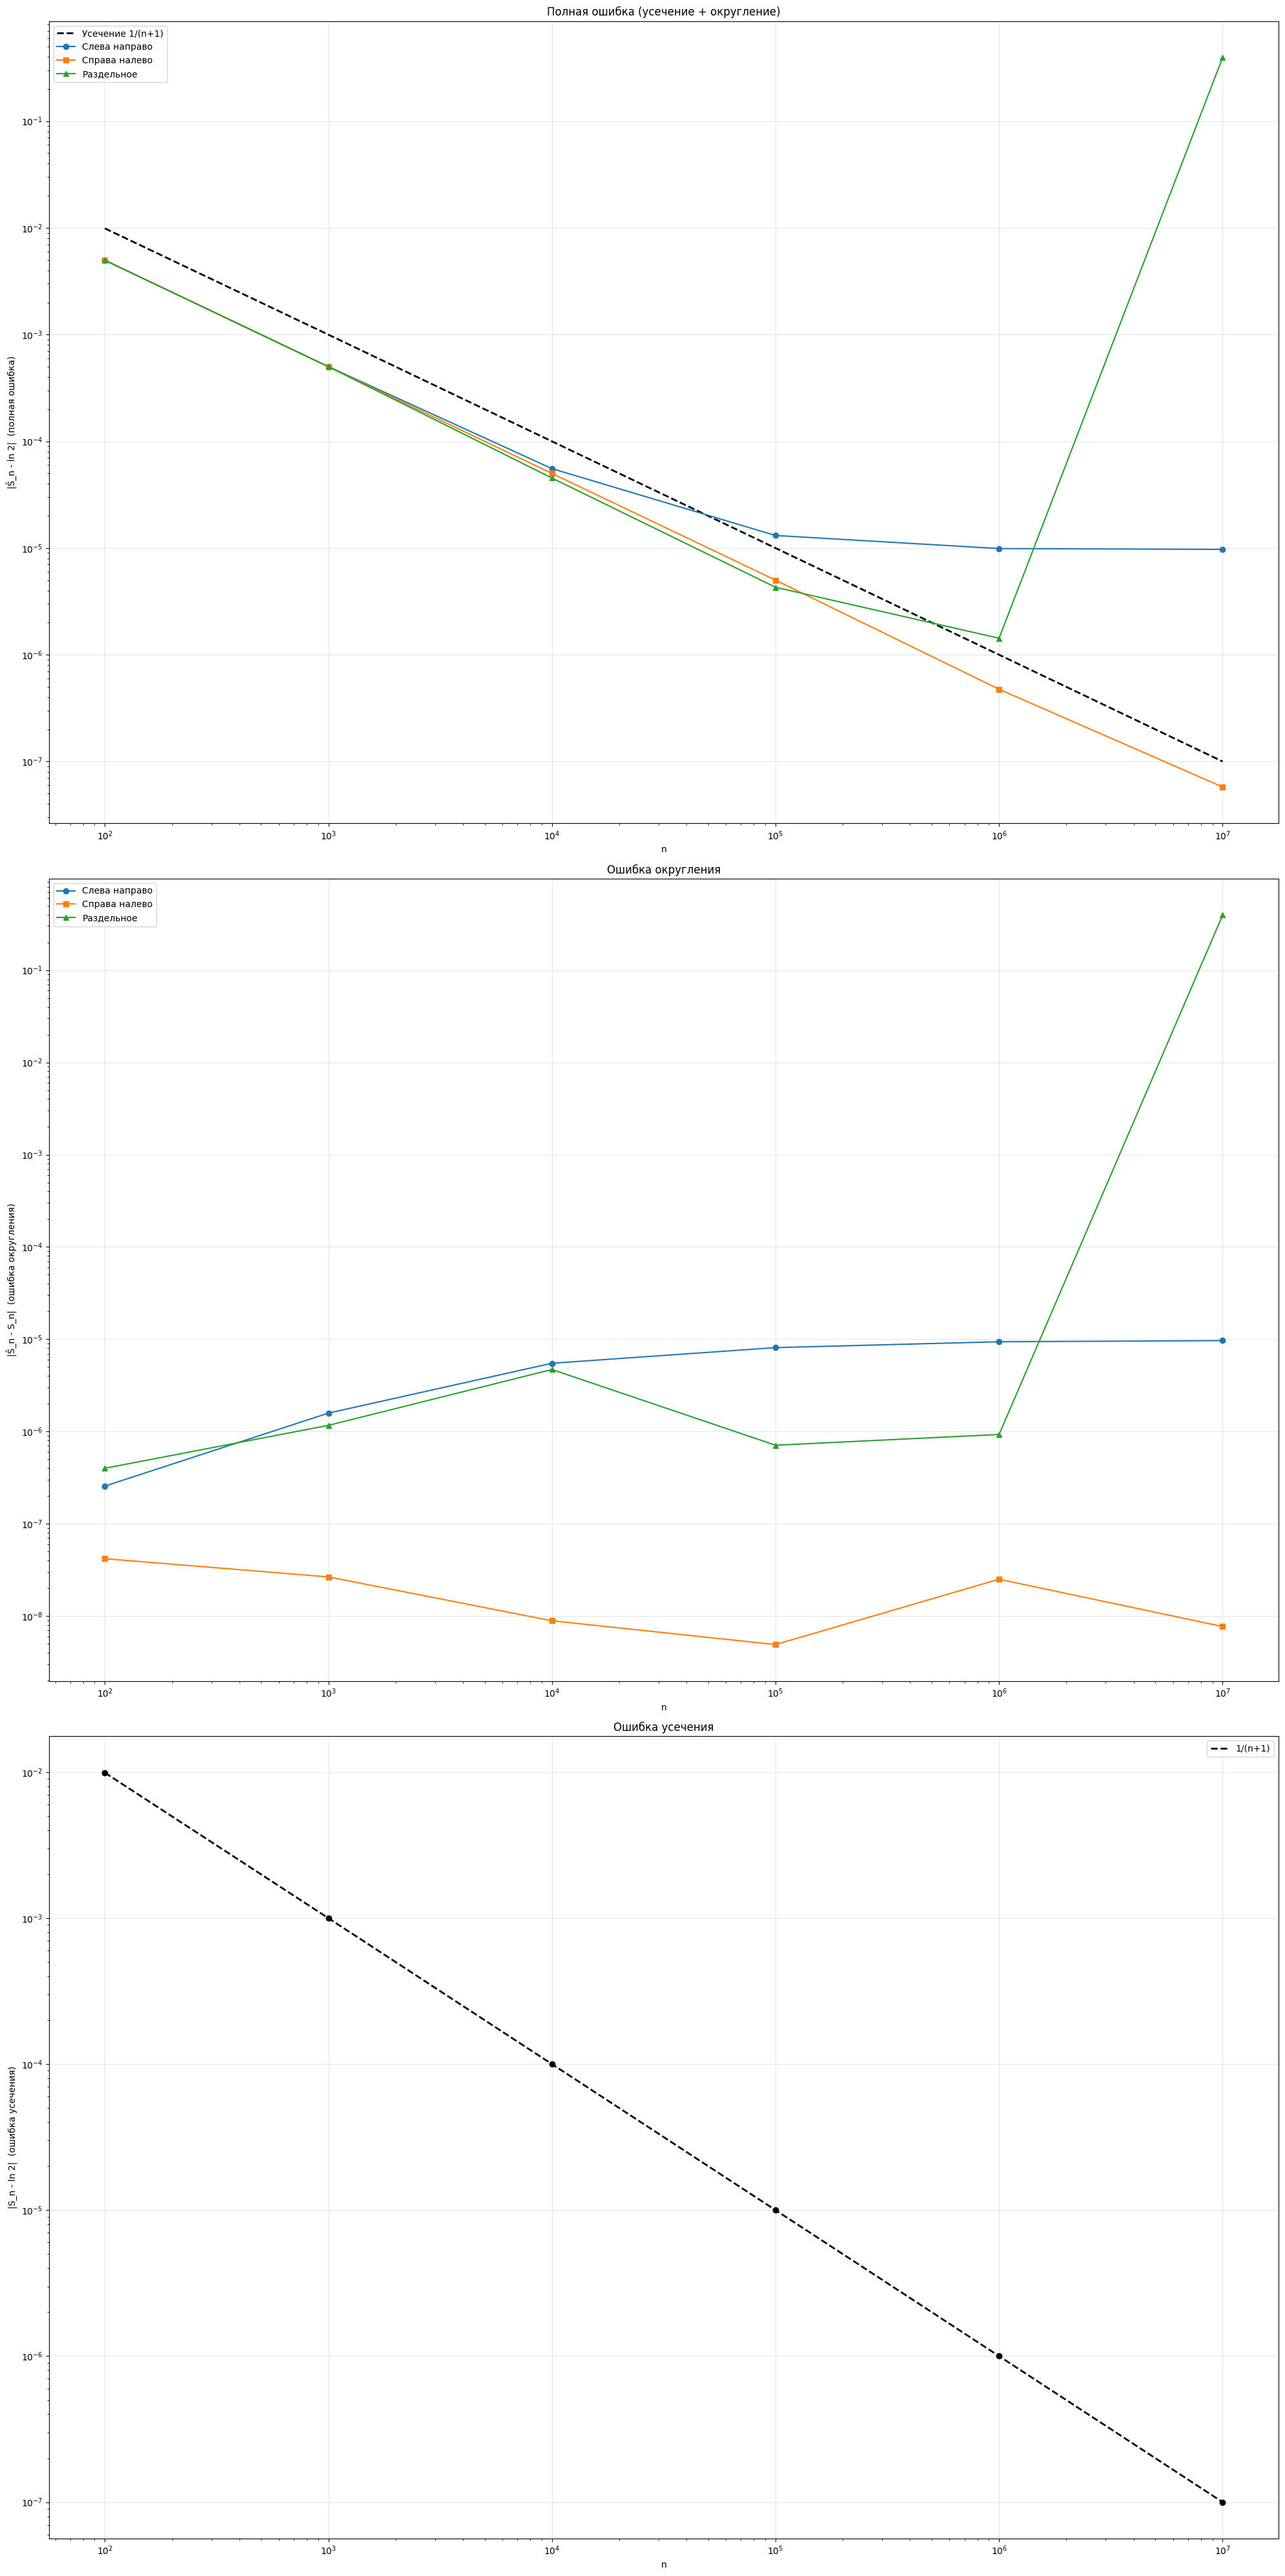

In [24]:
ns_arr = np.array(ns)
trunc_arr = np.array([r['trunc'] for r in results])

round_lr = np.array([r['round_lr'] for r in results])
round_rl = np.array([r['round_rl'] for r in results])
round_sep = np.array([r['round_sep'] for r in results])

full_lr = np.array([r['full_lr'] for r in results])
full_rl = np.array([r['full_rl'] for r in results])
full_sep = np.array([r['full_sep'] for r in results])

fig, axes = plt.subplots(3, 1, figsize=(20, 40))

ax = axes[0]
ax.loglog(ns_arr, trunc_arr, 'k--', label='Усечение 1/(n+1)', linewidth=2)
ax.loglog(ns_arr, full_lr, 'o-', label='Слева направо')
ax.loglog(ns_arr, full_rl, 's-', label='Справа налево')
ax.loglog(ns_arr, full_sep, '^-', label='Раздельное')
ax.set_xlabel('n'); ax.set_ylabel('|Ŝ_n - ln 2|  (полная ошибка)')
ax.set_title('Полная ошибка (усечение + округление)'); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.loglog(ns_arr, round_lr, 'o-', label='Слева направо')
ax.loglog(ns_arr, round_rl, 's-', label='Справа налево')
ax.loglog(ns_arr, round_sep, '^-', label='Раздельное')
ax.set_xlabel('n'); ax.set_ylabel('|Ŝ_n - S_n|  (ошибка округления)')
ax.set_title('Ошибка округления'); ax.legend(); ax.grid(alpha=0.3)

ax = axes[2]
ax.loglog(ns_arr, trunc_arr, 'k--', label='1/(n+1)', linewidth=2)
ax.loglog(ns_arr, trunc_arr, 'ko', markersize=6)
ax.set_xlabel('n'); ax.set_ylabel('|S_n - ln 2|  (ошибка усечения)')
ax.set_title('Ошибка усечения'); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


- Пунктирная линия $1/(n+1)$ — прямая в лог-лог координатах, потому что это степенная зависимость $n^{-1}$: наклон $-1$.
- На графике (полная ошибка) при малых $n$ все кривые почти сливаются с линией усечения — округление там пока не заметно на фоне того, что мы просто отбросили хвост ряда. При больших $n$ ($n\gtrsim10^5$–$10^6$) кривая усечения продолжает падать, а ошибка округления выходит на "пол" — суммарная ошибка перестаёт уменьшаться и определяется уже не математикой ряда, а конечной точностью `float32`.

## Выводы

1. **Где преобладает ошибка усечения, а где округления.** При малых и средних $n$ (пока $1/(n+1)$ ещё «крупная» величина по сравнению с $u_{32}\approx6\cdot10^{-8}$) главный вклад в суммарную ошибку — усечение ряда. Начиная примерно с $n\sim10^5$–$10^6$ усечение становится настолько маленьким, что суммарную ошибку определяет уже накопленное округление, и дальнейшее увеличение $n$ почти не улучшает результат (а для «плохих» методов может даже ухудшить).

2. **Почему порядок суммирования меняет результат.** Сложение с плавающей точкой неассоциативно (п. 5–6): каждая промежуточная сумма округляется, и то, что именно округляется — «мелкое к крупному» или «крупное к мелкому» — зависит от порядка. Суммирование от меньших слагаемых к большим (справа налево) обычно точнее, потому что мелкие слагаемые успевают накопиться друг с другом до потери значимости.

3. **Почему раздельное суммирование может быть неудачным.** Суммы $S^+$ и $S^-$ — обе величины порядка $\ln2$, близкие по модулю и противоположные по знаку. При их сложении происходит катастрофическое сокращение старших разрядов, и в результате "всплывает" ранее накопленная (в каждой из двух сумм) ошибка округления в виде куда большей *относительной* погрешности итога.

4. **Какой алгоритм оказался лучшим и по какому критерию.** По критерию минимальной ошибки округления при фиксированном $n$ обычно выигрывает суммирование **справа налево** (от мелких слагаемых к крупным) — оно даёт наименьшую `round_*` ошибку среди трёх «наивных» методов. Раздельное суммирование — систематически худший вариант из-за катастрофического сокращения. (Ещё лучше был бы алгоритм компенсированного суммирования Кэхэна, который как раз использован в контрольной сумме `control_sum` через `math.fsum`.)

In [16]:
one = np.float32(1.0)
d = np.float32(1e-16)
u = eps32 / np.float32(2.0)

s = one + d       # fl(1+d)
A = s + d         # fl( fl(1+d) + d )  -- складываем d по одному

t = d + d         # fl(d+d) -- точная операция, т.к. оба слагаемых d
B = one + t       # fl( 1 + fl(d+d) )  -- сначала сложили маленькие числа

print("d =", float(d), " d < u:", d < u)
print("s = fl(1+d)   =", float(s))
print("A = (1+d)+d   =", float(A))
print("t = fl(d+d)   =", float(t))
print("B = 1+(d+d)   =", float(B))
print("A == B ?", A == B)

d = 1.0000000168623835e-16  d < u: True
s = fl(1+d)   = 1.0
A = (1+d)+d   = 1.0
t = fl(d+d)   = 2.000000033724767e-16
B = 1+(d+d)   = 1.0
A == B ? True


In [17]:
def timeit_best_of(func, *args, repeat=5):
    """Возвращает минимальное время выполнения func(*args) из `repeat` запусков
    и сам результат последнего вызова (чтобы не считать функцию ещё раз)."""
    best = math.inf
    result = None
    for _ in range(repeat):
        t0 = time.perf_counter()
        result = func(*args)
        dt = time.perf_counter() - t0
        best = min(best, dt)
    return best, result

# измеряем время и ошибку для каждого метода при разных n
timing_results = {"lr": [], "rl": [], "sep": []}

for n in ns:
    a = terms(n, np.float32)
    Sn = control_sum(n)

    t_lr, S_lr = timeit_best_of(sum_left_to_right, a, np.float32)
    t_rl, S_rl = timeit_best_of(sum_right_to_left, a, np.float32)
    t_sep, S_sep = timeit_best_of(sum_separately, a, np.float32)

    timing_results["lr"].append((n, t_lr, abs(float(S_lr) - ln2)))
    timing_results["rl"].append((n, t_rl, abs(float(S_rl) - ln2)))
    timing_results["sep"].append((n, t_sep, abs(float(S_sep) - ln2)))

for name, rows in timing_results.items():
    print(name, ":")
    for n, t, err in rows:
        print(f"  n={n:8d}  время={t:9.5f} с   ошибка={err:.3e}")


lr :
  n=     100  время=  0.00001 с   ошибка=4.975e-03
  n=    1000  время=  0.00005 с   ошибка=5.013e-04
  n=   10000  время=  0.00049 с   ошибка=5.549e-05
  n=  100000  время=  0.00473 с   ошибка=1.311e-05
  n= 1000000  время=  0.04847 с   ошибка=9.892e-06
  n=10000000  время=  0.46450 с   ошибка=9.714e-06
rl :
  n=     100  время=  0.00001 с   ошибка=4.975e-03
  n=    1000  время=  0.00005 с   ошибка=4.997e-04
  n=   10000  время=  0.00050 с   ошибка=5.001e-05
  n=  100000  время=  0.00468 с   ошибка=5.005e-06
  n= 1000000  время=  0.04824 с   ошибка=4.749e-07
  n=10000000  время=  0.45602 с   ошибка=5.770e-08
sep :
  n=     100  время=  0.00001 с   ошибка=4.975e-03
  n=    1000  время=  0.00009 с   ошибка=5.009e-04
  n=   10000  время=  0.00086 с   ошибка=4.530e-05
  n=  100000  время=  0.00918 с   ошибка=4.290e-06
  n= 1000000  время=  0.08743 с   ошибка=1.429e-06
  n=10000000  время=  0.85031 с   ошибка=3.950e-01


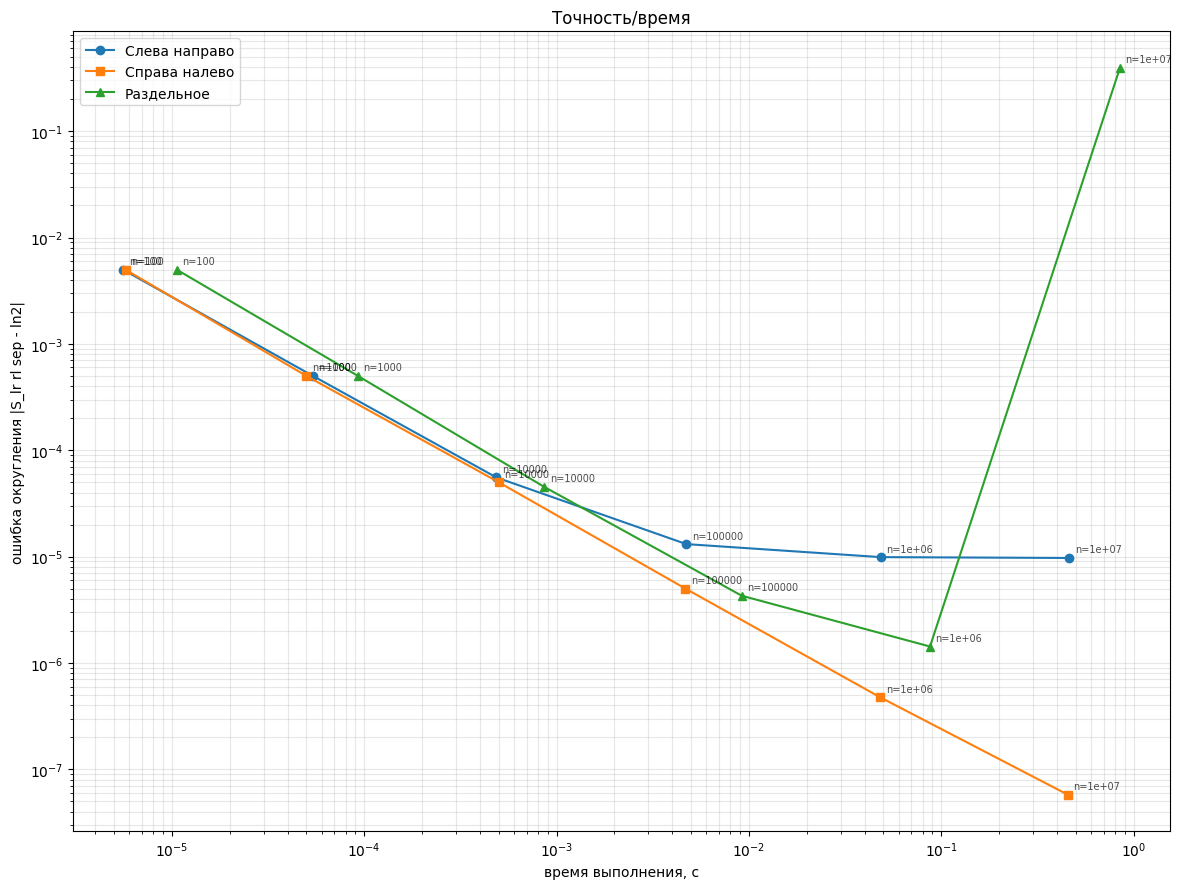

In [27]:
fig, ax = plt.subplots(figsize=(12, 9))

markers = {"lr": "o-", "rl": "s-", "sep": "^-"}
labels = {"lr": "Слева направо", "rl": "Справа налево", "sep": "Раздельное"}

for name, rows in timing_results.items():
    times = [t for (n, t, err) in rows]
    errs = [err for (n, t, err) in rows]
    ax.loglog(times, errs, markers[name], label=labels[name])
    for n, t, err in rows:
        ax.annotate(f"n={n:g}", (t, err), fontsize=7, alpha=0.7,
                    textcoords="offset points", xytext=(4, 4))

ax.set_xlabel("время выполнения, с")
ax.set_ylabel("ошибка округления |S_lr rl sep - ln2|")
ax.set_title("Точность/время")
ax.legend()
ax.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()


In [ ]:
def time_to_reach_epsilon(sum_func, eps, n_measure=2000000, dtype=np.float32):
    
    a = terms(n_measure, dtype)

    t0 = time.perf_counter()
    sum_func(a, dtype)
    dt = time.perf_counter() - t0

    per_op = dt / n_measure
    n_target = 1 / eps32 - 1
    T_seconds = n_target * per_op

    print(f"измерено на n={n_measure}: {per_op:.3e} c/операция")
    print(f"нужно n = {n_target:.3e} слагаемых")
    print(f"оценка времени = {T_seconds:.3e} c "
          f"= {T_seconds/3600:.1f} ч "
          f"= {T_seconds/(365.25*24*3600):.2f} лет")
    return T_seconds

time_to_reach_epsilon(sum_left_to_right, eps32)

измерено на n=2000000: 5.773e-08 c/операция
нужно n = 8.389e+06 слагаемых
оценка времени = 4.843e-01 c = 0.0 ч = 0.00 лет


np.float32(0.48427463)

In [49]:
print(type(eps))

<class 'numpy.float64'>
